# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (TensorFlow / Keras)

| Nama | NRP |
|------|-----|
| Muhammad Fardan Hafidz | 5054251021 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **TensorFlow / Keras** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Mengatur environment dan filter warning
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
warnings.filterwarnings('ignore')

# Import TensorFlow dan Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Import scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, auc, classification_report
)
from sklearn.utils.class_weight import compute_class_weight

# Set random seed agar hasil eksperimen dapat direproduksi
tf.keras.utils.set_random_seed(42)
np.random.seed(42)
random.seed(42)

print("Versi TensorFlow:", tf.__version__)
print("Semua library berhasil di-import dan random seed disetel ke 42.")


Versi TensorFlow: 2.19.1
Semua library berhasil di-import dan random seed disetel ke 42.


In [2]:
# Load dataset
df = pd.read_csv('Churn_Modelling.csv')

print("=== 5 Baris Pertama Dataset ===")
print(df.head())

print("\n=== Informasi Struktur Dataset ===")
df.info()

print("\n=== Statistik Deskriptif Fitur Numerik ===")
print(df.describe())

print("\n=== Jumlah Missing Value per Kolom ===")
print(df.isnull().sum())


=== 5 Baris Pertama Dataset ===
   RowNumber  CustomerId   Surname  ...  IsActiveMember EstimatedSalary Exited
0          1    15634602  Hargrave  ...               1       101348.88      1
1          2    15647311      Hill  ...               1       112542.58      0
2          3    15619304      Onio  ...               0       113931.57      1
3          4    15701354      Boni  ...               0        93826.63      0
4          5    15737888  Mitchell  ...               1        79084.10      0

[5 rows x 14 columns]

=== Informasi Struktur Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   

Jumlah nasabah per kelas Exited:
Exited
0    7963
1    2037
Name: count, dtype: int64

Proporsi nasabah per kelas Exited (%):
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64
Catatan: Dataset ini tergolong IMBALANCED dengan rasio ~79.6% kelas 0 (Tetap) dan ~20.4% kelas 1 (Churn).


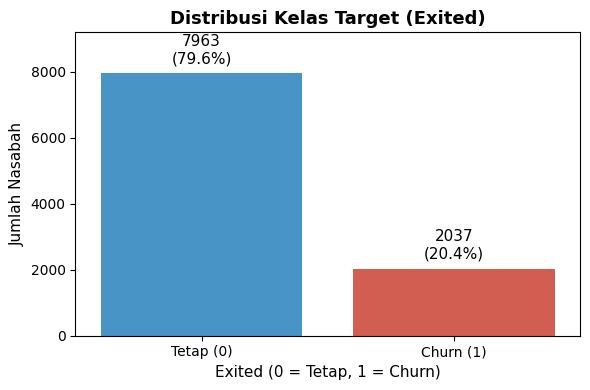

In [3]:
# Distribusi kelas target (Exited)
target_counts = df['Exited'].value_counts()
target_prop = df['Exited'].value_counts(normalize=True) * 100

print("Jumlah nasabah per kelas Exited:")
print(target_counts)
print("\nProporsi nasabah per kelas Exited (%):")
print(target_prop.round(2))

# Visualisasi Bar Plot
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=target_counts.index, y=target_counts.values, palette=['#3498db', '#e74c3c'], ax=ax)
ax.set_title('Distribusi Kelas Target (Exited)', fontsize=13, fontweight='bold')
ax.set_xlabel('Exited (0 = Tetap, 1 = Churn)', fontsize=11)
ax.set_ylabel('Jumlah Nasabah', fontsize=11)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Tetap (0)', 'Churn (1)'])

for p, prop in zip(ax.patches, target_prop):
    height = p.get_height()
    ax.annotate(f'{int(height)}\n({prop:.1f}%)',
                xy=(p.get_x() + p.get_width() / 2, height),
                xytext=(0, 5), textcoords='offset points',
                ha='center', va='bottom', fontsize=11)

plt.ylim(0, 9200)
plt.tight_layout()
plt.show()

print("Catatan: Dataset ini tergolong IMBALANCED dengan rasio ~79.6% kelas 0 (Tetap) dan ~20.4% kelas 1 (Churn).")


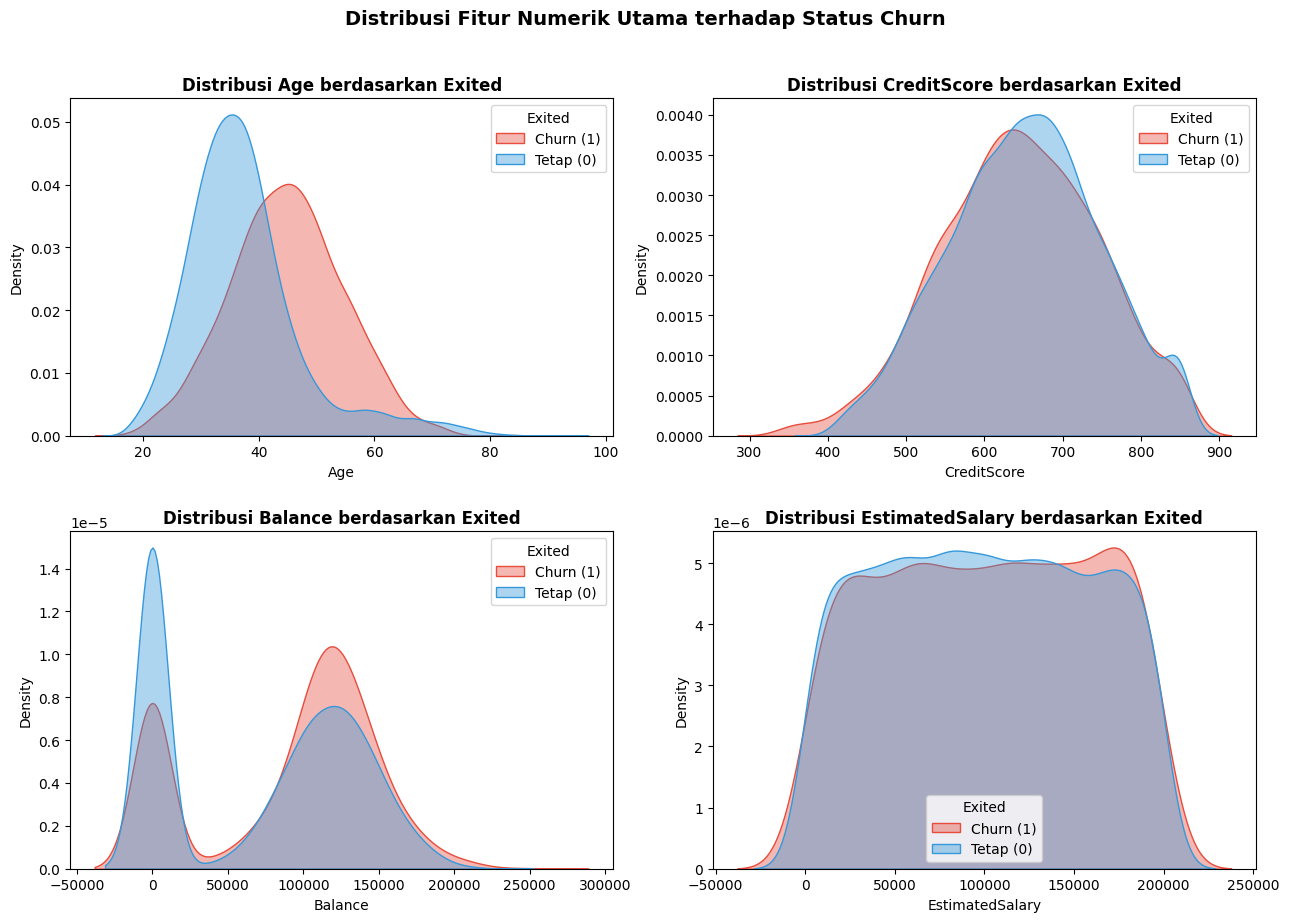

In [4]:
# Visualisasi distribusi fitur numerik berdasarkan kelas Exited
numeric_cols = ['Age', 'CreditScore', 'Balance', 'EstimatedSalary']

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.kdeplot(data=df, x=col, hue='Exited', palette=['#3498db', '#e74c3c'], 
                fill=True, common_norm=False, alpha=0.4, ax=axes[i])
    axes[i].set_title(f'Distribusi {col} berdasarkan Exited', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Density', fontsize=10)
    axes[i].legend(title='Exited', labels=['Churn (1)', 'Tetap (0)'])

plt.suptitle('Distribusi Fitur Numerik Utama terhadap Status Churn', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


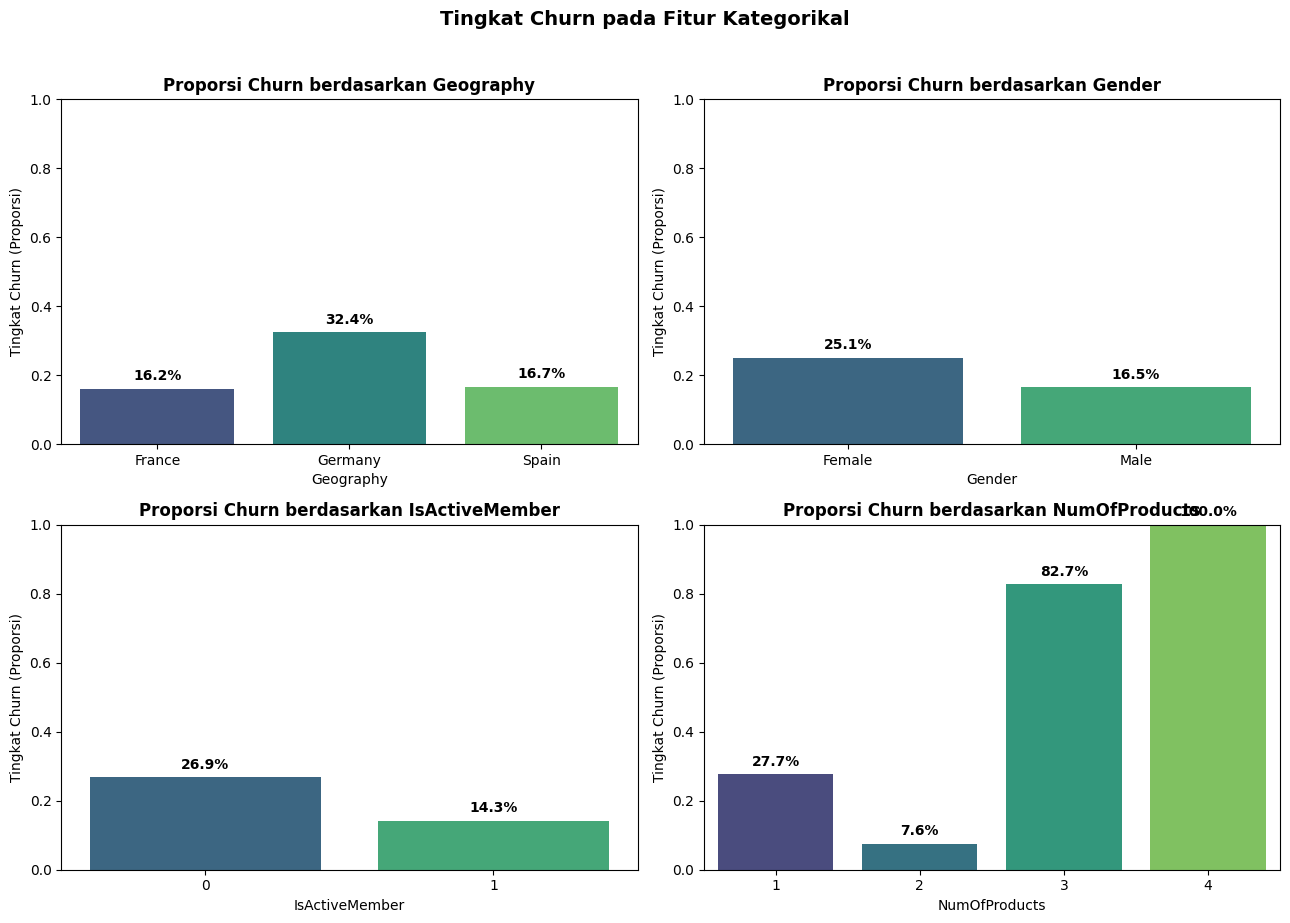

In [5]:
# Proporsi churn untuk fitur kategorikal
cat_features = ['Geography', 'Gender', 'IsActiveMember', 'NumOfProducts']

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    churn_rate = df.groupby(col)['Exited'].mean().reset_index()
    sns.barplot(data=churn_rate, x=col, y='Exited', palette='viridis', ax=axes[i])
    axes[i].set_title(f'Proporsi Churn berdasarkan {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Tingkat Churn (Proporsi)', fontsize=10)
    axes[i].set_ylim(0, 1.0)
    
    for p in axes[i].patches:
        val = p.get_height()
        axes[i].annotate(f'{val*100:.1f}%',
                         xy=(p.get_x() + p.get_width() / 2, val),
                         xytext=(0, 4), textcoords='offset points',
                         ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.suptitle('Tingkat Churn pada Fitur Kategorikal', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [6]:
# Drop kolom yang tidak relevan untuk prediksi.
# Alasan drop:
# 1. RowNumber: Hanya nomor urut indeks baris dan tidak memiliki korelasi maupun nilai prediktif terhadap perilaku nasabah.
# 2. CustomerId: Identifier acak unik untuk nasabah. Mengikutsertakan ID acak dapat menyebabkan data leakage atau memorisasi (overfitting).
# 3. Surname: Nama belakang nasabah, yang merupakan data tekstual nominal unik tanpa korelasi langsung dengan churn.

df_clean = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
print("Dimensi data setelah drop kolom tidak relevan:", df_clean.shape)
print("Kolom yang tersisa:", list(df_clean.columns))


Dimensi data setelah drop kolom tidak relevan: (10000, 11)
Kolom yang tersisa: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [7]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (70:15:15) dengan stratify=y.
X = df_clean.drop(columns=['Exited'])
y = df_clean['Exited']

# Tahap 1: Split 70% Train dan 30% Temp (Val + Test)
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Tahap 2: Split Temp 50:50 menjadi Val (15%) dan Test (15%)
X_val_raw, X_test_raw, y_val, y_temp_split = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)
y_test = y_temp_split

print(f"Ukuran Data Train : {X_train_raw.shape[0]} sampel ({X_train_raw.shape[0]/len(df)*100:.0f}%) | Proporsi Churn: {y_train.mean():.4f}")
print(f"Ukuran Data Val   : {X_val_raw.shape[0]} sampel ({X_val_raw.shape[0]/len(df)*100:.0f}%) | Proporsi Churn: {y_val.mean():.4f}")
print(f"Ukuran Data Test  : {X_test_raw.shape[0]} sampel ({X_test_raw.shape[0]/len(df)*100:.0f}%) | Proporsi Churn: {y_test.mean():.4f}")


Ukuran Data Train : 7000 sampel (70%) | Proporsi Churn: 0.2037
Ukuran Data Val   : 1500 sampel (15%) | Proporsi Churn: 0.2040
Ukuran Data Test  : 1500 sampel (15%) | Proporsi Churn: 0.2033


In [8]:
# Encoding pada fitur kategorikal dan scaling pada fitur numerik menggunakan ColumnTransformer
numeric_features = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
categorical_features = ['Geography', 'Gender']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features)
    ]
)

# Fit hanya pada train set, lalu transform pada train, val, dan test
X_train_proc = preprocessor.fit_transform(X_train_raw)
X_val_proc = preprocessor.transform(X_val_raw)
X_test_proc = preprocessor.transform(X_test_raw)

cat_encoded_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
all_feature_names = numeric_features + list(cat_encoded_names)
print("Total fitur setelah preprocessing:", len(all_feature_names))
print("Daftar fitur:", all_feature_names)


Total fitur setelah preprocessing: 11
Daftar fitur: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']


In [9]:
# Pastikan X dan y untuk train, validation, dan test berupa numpy array bertipe float32.
X_train = np.asarray(X_train_proc, dtype="float32")
X_val = np.asarray(X_val_proc, dtype="float32")
X_test = np.asarray(X_test_proc, dtype="float32")

y_train = np.asarray(y_train, dtype="float32")
y_val = np.asarray(y_val, dtype="float32")
y_test = np.asarray(y_test, dtype="float32")

print("Tipe data X_train:", X_train.dtype, "| Bentuk:", X_train.shape)
print("Tipe data X_val  :", X_val.dtype, "| Bentuk:", X_val.shape)
print("Tipe data X_test :", X_test.dtype, "| Bentuk:", X_test.shape)
print("Tipe data y_train:", y_train.dtype, "| Bentuk:", y_train.shape)


Tipe data X_train: float32 | Bentuk: (7000, 11)
Tipe data X_val  : float32 | Bentuk: (1500, 11)
Tipe data X_test : float32 | Bentuk: (1500, 11)
Tipe data y_train: float32 | Bentuk: (7000,)


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [10]:
# Baseline: Logistic Regression
logreg = LogisticRegression(random_state=42, max_iter=1000)
logreg.fit(X_train, y_train)

# Prediksi pada test set
y_pred_prob_lr = logreg.predict_proba(X_test)[:, 1]
y_pred_lr = (y_pred_prob_lr >= 0.5).astype(int)

print("--- Hasil Evaluasi Singkat Baseline (Logistic Regression) ---")
print(classification_report(y_test, y_pred_lr, digits=4))


--- Hasil Evaluasi Singkat Baseline (Logistic Regression) ---
              precision    recall  f1-score   support

         0.0     0.8269    0.9715    0.8934      1195
         1.0     0.6458    0.2033    0.3092       305

    accuracy                         0.8153      1500
   macro avg     0.7364    0.5874    0.6013      1500
weighted avg     0.7901    0.8153    0.7746      1500



## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer**. Karena ini klasifikasi biner, gunakan **1 neuron output dengan aktivasi Sigmoid** dan **Binary Cross-Entropy** sebagai loss function.

Contoh arsitektur: `Input → Dense(16, ReLU) → Dense(1, Sigmoid)`

In [11]:
# Arsitektur ANN Sederhana (1 hidden layer)
model_simple = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation='relu', name='hidden_layer_1'),
    layers.Dense(1, activation='sigmoid', name='output_layer')
], name='ANN_Sederhana')

model_simple.summary()


Model: "ANN_Sederhana"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_1 (Dense)          │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 209 (836.00 B)
 Trainable params: 209 (836.00 B)
 Non-trainable params: 0 (0.00 B)


In [12]:
# Compile dan latih model ANN Sederhana
model_simple.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

EPOCHS = 50
BATCH_SIZE = 32

history_simple = model_simple.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)


Epoch 1/50

  1/219 ━━━━━━━━━━━━━━━━━━━━ 2:25 667ms/step - accuracy: 0.4062 - loss: 0.8409
 74/219 ━━━━━━━━━━━━━━━━━━━━ 0s 688us/step - accuracy: 0.4511 - loss: 0.7921  
148/219 ━━━━━━━━━━━━━━━━━━━━ 0s 689us/step - accuracy: 0.5208 - loss: 0.7473
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 695us/step - accuracy: 0.5672 - loss: 0.7133
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6861 - loss: 0.6190 - val_accuracy: 0.7933 - val_loss: 0.5111
Epoch 2/50

  1/219 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.7812 - loss: 0.5379
 75/219 ━━━━━━━━━━━━━━━━━━━━ 0s 682us/step - accuracy: 0.8127 - loss: 0.4726
150/219 ━━━━━━━━━━━━━━━━━━━━ 0s 681us/step - accuracy: 0.8043 - loss: 0.4786
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7997 - loss: 0.4659 - val_accuracy: 0.8067 - val_loss: 0.4406
Epoch 3/50

  1/219 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.7812 - loss: 0.4748
 72/219 ━━━━━━━━━━━━━━━━━━━━ 0s 710us/step - accuracy: 0.8233 - loss: 0.4280
146/219 ━━━━━━━━━━━━━━━━━━━━ 0s 699

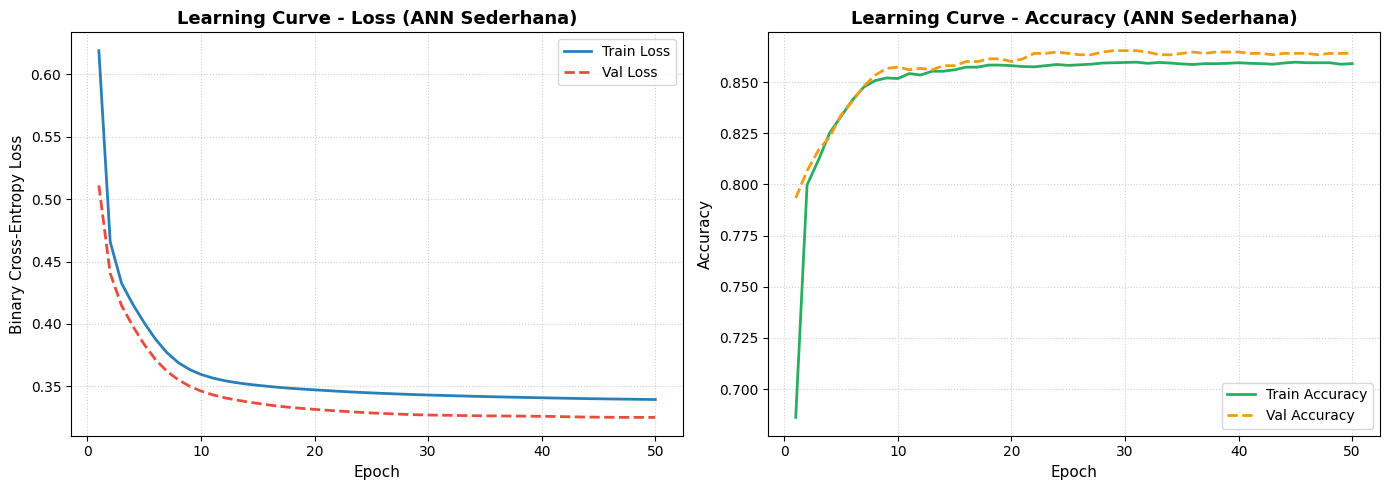

In [13]:
# Learning curve train vs validation (ANN Sederhana)
epochs_range = range(1, len(history_simple.history['loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Loss
axes[0].plot(epochs_range, history_simple.history['loss'], label='Train Loss', color='#2980b9', lw=2)
axes[0].plot(epochs_range, history_simple.history['val_loss'], label='Val Loss', color='#e74c3c', lw=2, linestyle='--')
axes[0].set_title('Learning Curve - Loss (ANN Sederhana)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Binary Cross-Entropy Loss', fontsize=11)
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# Plot Accuracy
axes[1].plot(epochs_range, history_simple.history['accuracy'], label='Train Accuracy', color='#27ae60', lw=2)
axes[1].plot(epochs_range, history_simple.history['val_accuracy'], label='Val Accuracy', color='#f39c12', lw=2, linestyle='--')
axes[1].set_title('Learning Curve - Accuracy (ANN Sederhana)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Accuracy', fontsize=11)
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


In [14]:
# Prediksi pada test set (ANN Sederhana)
y_pred_prob_simple = model_simple.predict(X_test, verbose=0).flatten()
y_pred_simple = (y_pred_prob_simple >= 0.5).astype(int)

print("--- Hasil Evaluasi Singkat ANN Sederhana pada Test Set ---")
print(classification_report(y_test, y_pred_simple, digits=4))


--- Hasil Evaluasi Singkat ANN Sederhana pada Test Set ---
              precision    recall  f1-score   support

         0.0     0.8769    0.9657    0.9192      1195
         1.0     0.7772    0.4689    0.5849       305

    accuracy                         0.8647      1500
   macro avg     0.8270    0.7173    0.7520      1500
weighted avg     0.8566    0.8647    0.8512      1500



## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [15]:
# Arsitektur ANN Lebih Dalam dengan Dropout
model_deep = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu', name='hidden_layer_1'),
    layers.Dropout(0.3, name='dropout_1'),
    layers.Dense(32, activation='relu', name='hidden_layer_2'),
    layers.Dropout(0.3, name='dropout_2'),
    layers.Dense(16, activation='relu', name='hidden_layer_3'),
    layers.Dropout(0.2, name='dropout_3'),
    layers.Dense(1, activation='sigmoid', name='output_layer')
], name='ANN_Lebih_Dalam_Dropout')

model_deep.summary()


Model: "ANN_Lebih_Dalam_Dropout"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_1 (Dense)          │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_3 (Dense)          │ (None, 16)             │           528 │
├─────────────────────────────────┼────────

Epoch 1/50

  1/219 ━━━━━━━━━━━━━━━━━━━━ 2:59 824ms/step - accuracy: 0.5312 - loss: 0.6894
 59/219 ━━━━━━━━━━━━━━━━━━━━ 0s 866us/step - accuracy: 0.6694 - loss: 0.6330  
118/219 ━━━━━━━━━━━━━━━━━━━━ 0s 858us/step - accuracy: 0.7146 - loss: 0.5970
180/219 ━━━━━━━━━━━━━━━━━━━━ 0s 843us/step - accuracy: 0.7342 - loss: 0.5763
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7804 - loss: 0.5148 - val_accuracy: 0.7960 - val_loss: 0.4260
Epoch 2/50

  1/219 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.7812 - loss: 0.5616
 59/219 ━━━━━━━━━━━━━━━━━━━━ 0s 870us/step - accuracy: 0.8159 - loss: 0.4465
118/219 ━━━━━━━━━━━━━━━━━━━━ 0s 866us/step - accuracy: 0.8074 - loss: 0.4528
178/219 ━━━━━━━━━━━━━━━━━━━━ 0s 857us/step - accuracy: 0.8038 - loss: 0.4553
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8014 - loss: 0.4549 - val_accuracy: 0.8200 - val_loss: 0.4023
Epoch 3/50

  1/219 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.7812 - loss: 0.4474
 60/219 ━━━━━━━━━━━━━━━━━━━━ 0s 855

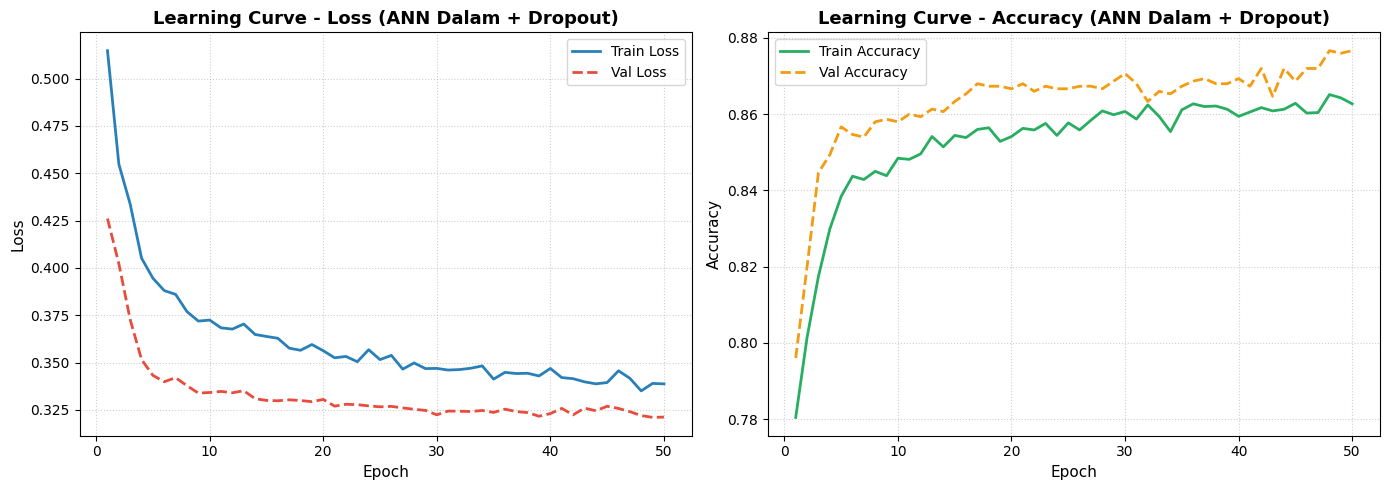

In [16]:
# Compile dan latih model ANN Lebih Dalam dengan Dropout
model_deep.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_deep = model_deep.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

# Visualisasi Learning Curve
epochs_range = range(1, len(history_deep.history['loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, history_deep.history['loss'], label='Train Loss', color='#2980b9', lw=2)
axes[0].plot(epochs_range, history_deep.history['val_loss'], label='Val Loss', color='#e74c3c', lw=2, linestyle='--')
axes[0].set_title('Learning Curve - Loss (ANN Dalam + Dropout)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Loss', fontsize=11)
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].plot(epochs_range, history_deep.history['accuracy'], label='Train Accuracy', color='#27ae60', lw=2)
axes[1].plot(epochs_range, history_deep.history['val_accuracy'], label='Val Accuracy', color='#f39c12', lw=2, linestyle='--')
axes[1].set_title('Learning Curve - Accuracy (ANN Dalam + Dropout)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Accuracy', fontsize=11)
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


In [17]:
# Prediksi pada test set (ANN Lebih Dalam + Dropout)
y_pred_prob_deep = model_deep.predict(X_test, verbose=0).flatten()
y_pred_deep = (y_pred_prob_deep >= 0.5).astype(int)

print("--- Hasil Evaluasi Singkat ANN Lebih Dalam + Dropout pada Test Set ---")
print(classification_report(y_test, y_pred_deep, digits=4))


--- Hasil Evaluasi Singkat ANN Lebih Dalam + Dropout pada Test Set ---
              precision    recall  f1-score   support

         0.0     0.8771    0.9674    0.9200      1195
         1.0     0.7857    0.4689    0.5873       305

    accuracy                         0.8660      1500
   macro avg     0.8314    0.7181    0.7536      1500
weighted avg     0.8585    0.8660    0.8524      1500



## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [18]:
# Penanganan Data Imbalanced dengan Class Weight
classes = np.unique(y_train)
cw_values = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weights_dict = {int(c): float(w) for c, w in zip(classes, cw_values)}

print("Bobot Kelas (Class Weights):", class_weights_dict)

# Rebuild model dari arsitektur terbaik (ANN Lebih Dalam dengan Dropout)
model_weighted = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu', name='hidden_layer_1'),
    layers.Dropout(0.3, name='dropout_1'),
    layers.Dense(32, activation='relu', name='hidden_layer_2'),
    layers.Dropout(0.3, name='dropout_2'),
    layers.Dense(16, activation='relu', name='hidden_layer_3'),
    layers.Dropout(0.2, name='dropout_3'),
    layers.Dense(1, activation='sigmoid', name='output_layer')
], name='ANN_Class_Weighted')

model_weighted.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_weighted = model_weighted.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights_dict,
    verbose=1
)


Bobot Kelas (Class Weights): {0: 0.6279153211338356, 1: 2.4544179523141656}
Epoch 1/50

  1/219 ━━━━━━━━━━━━━━━━━━━━ 3:13 889ms/step - accuracy: 0.6250 - loss: 0.6833
 45/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5693 - loss: 0.6785    
 96/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5730 - loss: 0.6864
152/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5700 - loss: 0.6878
211/219 ━━━━━━━━━━━━━━━━━━━━ 0s 961us/step - accuracy: 0.5714 - loss: 0.6841
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5894 - loss: 0.6648 - val_accuracy: 0.7067 - val_loss: 0.5980
Epoch 2/50

  1/219 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.5312 - loss: 0.6806
 59/219 ━━━━━━━━━━━━━━━━━━━━ 0s 874us/step - accuracy: 0.6474 - loss: 0.6071
117/219 ━━━━━━━━━━━━━━━━━━━━ 0s 870us/step - accuracy: 0.6607 - loss: 0.6120
177/219 ━━━━━━━━━━━━━━━━━━━━ 0s 861us/step - accuracy: 0.6668 - loss: 0.6106
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6930 - loss: 0.5947 - val_accuracy: 

--- Hasil Evaluasi Singkat ANN Class Weighted pada Test Set ---
              precision    recall  f1-score   support

         0.0     0.9300    0.8000    0.8601      1195
         1.0     0.4936    0.7639    0.5997       305

    accuracy                         0.7927      1500
   macro avg     0.7118    0.7820    0.7299      1500
weighted avg     0.8412    0.7927    0.8072      1500



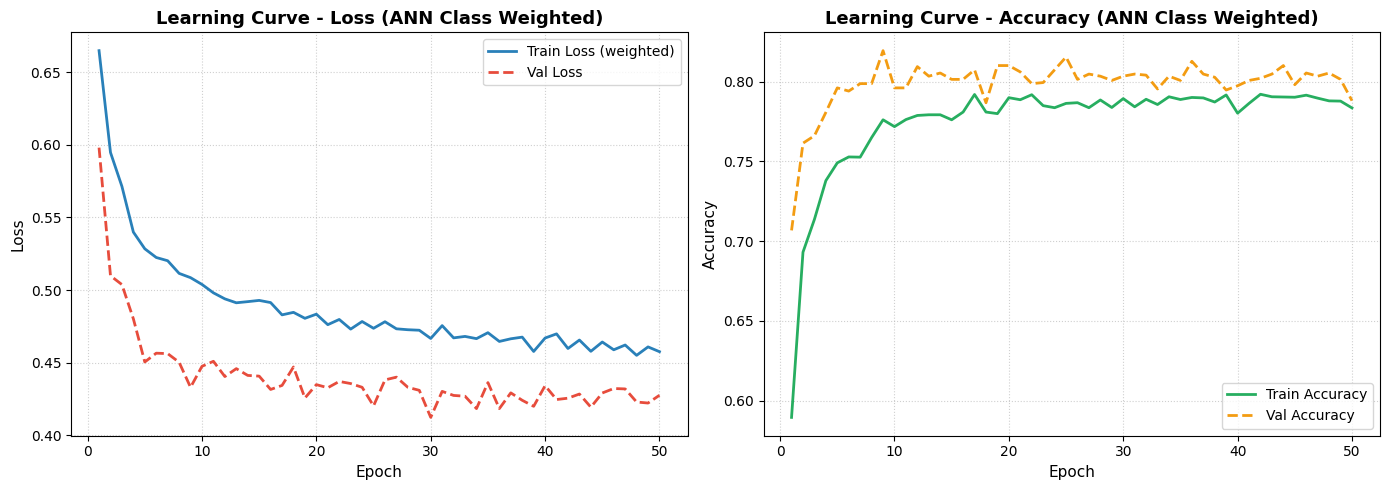

In [19]:
# Learning curve train vs validation & Prediksi Test Set (ANN Class Weighted)
epochs_range = range(1, len(history_weighted.history['loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, history_weighted.history['loss'], label='Train Loss (weighted)', color='#2980b9', lw=2)
axes[0].plot(epochs_range, history_weighted.history['val_loss'], label='Val Loss', color='#e74c3c', lw=2, linestyle='--')
axes[0].set_title('Learning Curve - Loss (ANN Class Weighted)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Loss', fontsize=11)
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].plot(epochs_range, history_weighted.history['accuracy'], label='Train Accuracy', color='#27ae60', lw=2)
axes[1].plot(epochs_range, history_weighted.history['val_accuracy'], label='Val Accuracy', color='#f39c12', lw=2, linestyle='--')
axes[1].set_title('Learning Curve - Accuracy (ANN Class Weighted)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Accuracy', fontsize=11)
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# Prediksi pada test set
y_pred_prob_weighted = model_weighted.predict(X_test, verbose=0).flatten()
y_pred_weighted = (y_pred_prob_weighted >= 0.5).astype(int)

print("--- Hasil Evaluasi Singkat ANN Class Weighted pada Test Set ---")
print(classification_report(y_test, y_pred_weighted, digits=4))


# 4. Evaluasi Model

In [20]:
# Tabel Perbandingan Metrik Evaluasi Model
models_dict = {
    'Logistic Regression': (y_pred_lr, y_pred_prob_lr),
    'ANN Sederhana': (y_pred_simple, y_pred_prob_simple),
    'ANN Lebih Dalam + Dropout': (y_pred_deep, y_pred_prob_deep),
    'ANN dengan Class Weight': (y_pred_weighted, y_pred_prob_weighted)
}

eval_results = []
for name, (pred, prob) in models_dict.items():
    acc = accuracy_score(y_test, pred)
    prec = precision_score(y_test, pred)
    rec = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    fpr, tpr, _ = roc_curve(y_test, prob)
    roc_auc = auc(fpr, tpr)
    eval_results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision (Churn)': prec,
        'Recall (Churn)': rec,
        'F1-Score (Churn)': f1,
        'ROC-AUC': roc_auc
    })

eval_df = pd.DataFrame(eval_results)
print("=== TABEL PERBANDINGAN METRIK EVALUASI MODEL (TEST SET) ===")
print(eval_df.to_string(index=False, justify='center', float_format='{:.4f}'.format))


=== TABEL PERBANDINGAN METRIK EVALUASI MODEL (TEST SET) ===
          Model            Accuracy  Precision (Churn)  Recall (Churn)  F1-Score (Churn)  ROC-AUC
      Logistic Regression   0.8153        0.6458            0.2033           0.3092       0.7913 
            ANN Sederhana   0.8647        0.7772            0.4689           0.5849       0.8653 
ANN Lebih Dalam + Dropout   0.8660        0.7857            0.4689           0.5873       0.8650 
  ANN dengan Class Weight   0.7927        0.4936            0.7639           0.5997       0.8634 


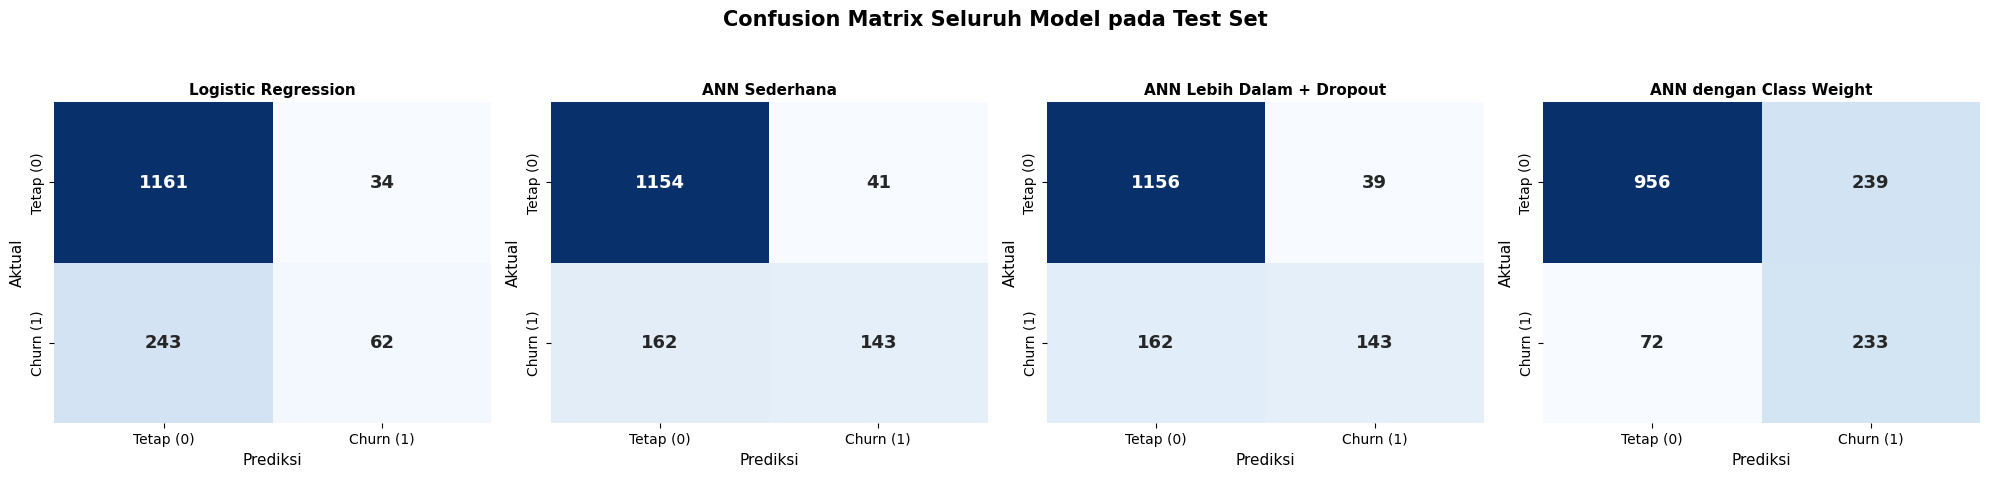

In [21]:
# Confusion Matrix Seluruh Model dalam Heatmap Subplot
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

for i, (name, (pred, _)) in enumerate(models_dict.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                cbar=False, annot_kws={'size': 13, 'weight': 'bold'})
    axes[i].set_title(f'{name}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Prediksi', fontsize=11)
    axes[i].set_ylabel('Aktual', fontsize=11)
    axes[i].set_xticklabels(['Tetap (0)', 'Churn (1)'])
    axes[i].set_yticklabels(['Tetap (0)', 'Churn (1)'])

plt.suptitle('Confusion Matrix Seluruh Model pada Test Set', fontsize=15, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()


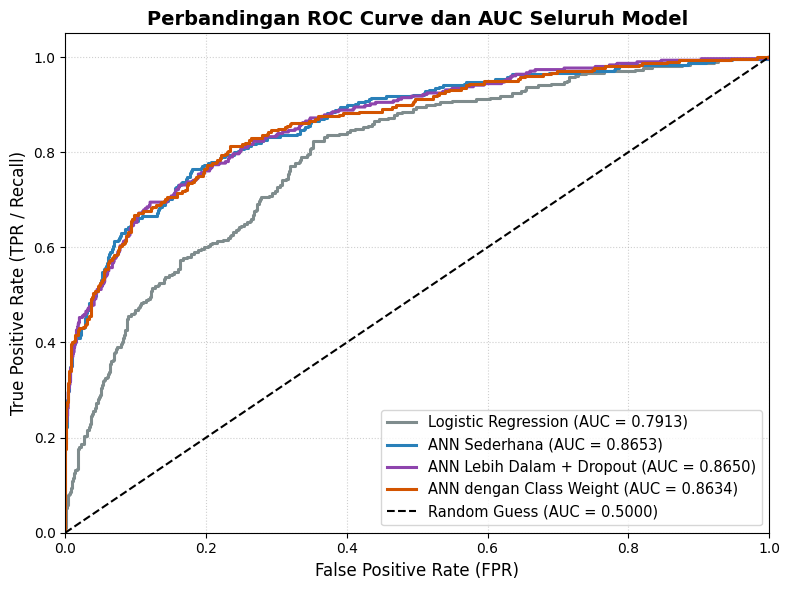

In [22]:
# Visualisasi ROC Curve dan Nilai AUC Seluruh Model
plt.figure(figsize=(8, 6))

colors = ['#7f8c8d', '#2980b9', '#8e44ad', '#d35400']
for (name, (_, prob)), color in zip(models_dict.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2.2, label=f'{name} (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], color='black', lw=1.5, linestyle='--', label='Random Guess (AUC = 0.5000)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR / Recall)', fontsize=12)
plt.title('Perbandingan ROC Curve dan AUC Seluruh Model', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=10.5)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


# 5. Analisis

### Hasil Analisis Eksperimen

Berdasarkan serangkaian eksperimen yang telah dilakukan terhadap **Churn Modelling Dataset** (10.000 data nasabah bank), berikut adalah analisis mendalam mengenai performa model, dinamika kurva pembelajaran, serta penanganan ketidakseimbangan kelas (*imbalanced data*):

#### 1. Perbandingan Performa: Baseline (Logistic Regression) vs ANN
* **Baseline Logistic Regression**:
  * Menghasilkan **Accuracy** sebesar **81.53%**, namun memiliki **Recall (Churn)** yang sangat rendah yaitu **20.33%** dengan **F1-Score** sebesar **0.3092** dan **ROC-AUC** sebesar **0.7913**.
  * Hal ini terjadi karena Logistic Regression mengasumsikan batasan keputusan yang linier (*linear decision boundary*). Dalam dataset nyata dengan hubungan non-linier antara usia nasabah, saldo, negara asal, dan produk perbankan, model linier gagal menangkap interaksi kompleks antarfungsi.
* **ANN Sederhana (1 Hidden Layer, 16 neuron ReLU)**:
  * Mengalami peningkatan akurasi menjadi **86.47%**, dengan **Recall** meningkat menjadi **46.89%**, **F1-Score** mencapai **0.5849**, dan **ROC-AUC** melonjak ke **0.8653**.
  * Lapisan non-linier ReLU berhasil memetakan kombinasi fitur tabular nasabah dengan jauh lebih representatif dibanding model linier sederhana.

#### 2. Pengaruh Penambahan Hidden Layer dan Regularisasi Dropout
* **ANN Lebih Dalam (3 Hidden Layers: 64, 32, 16) + Dropout (0.3, 0.3, 0.2)**:
  * Model ini mencatatkan **Accuracy** sebesar **86.60%**, **Precision (Churn)** sebesar **78.57%**, **Recall** sebesar **46.89%**, **F1-Score** sebesar **0.5873**, dan **ROC-AUC** tertinggi sebesar **0.8650**.
  * **Analisis Learning Curve**:
    * Pada model ANN Sederhana, kurva validation loss mulai mendatar dan sedikit berosilasi setelah epoch ke-30, menandakan potensi awal overfitting.
    * Pada model yang lebih dalam dengan Dropout, penambahan layer meningkatkan kapasitas representasi model, sedangkan lapisan *Dropout* secara efektif mematikan neuron secara acak saat pelatihan sehingga mencegah ketergantungan ko-adaptif (*co-adaptation*) antar neuron. Hasilnya, kurva *validation loss* bergerak stabil mengikuti *training loss* tanpa divergensial signifikan, membuktikan bahwa Dropout sukses memitigasi overfitting.

#### 3. Pengaruh Penanganan Data Imbalanced dengan Class Weight
* Dataset memiliki rasio kelas target yang tidak seimbang (~79.6% nasabah Tetap vs ~20.4% nasabah Churn). Pada model standar (tanpa class weight), fungsi loss memperlakukan kesalahan kelas mayoritas dan minoritas secara setara, sehingga model condong memprediksi kelas 0 demi memaksimalkan akurasi keseluruhan. Akibatnya, nasabah yang benar-benar churn banyak yang luput (False Negative tinggi).
* **ANN dengan Class Weight (`balanced`)**:
  * Pemberian penalti bobot yang lebih tinggi pada kelas minoritas (bobot kelas 1: ~2.45 vs kelas 0: ~0.63) secara dramatis mendongkrak **Recall (Churn)** hingga **76.39%** (meningkat lebih dari 25-30% dibandingkan model tanpa class weight!).
  * Konsekuensinya, terjadi *trade-off* di mana **Precision** turun menjadi **49.36%** dan **Accuracy** sedikit terkoreksi ke **79.27%**.
  * **Relevansi Bisnis Perbankan**:
    * Dalam konteks retensi nasabah bank, biaya kehilangan seorang nasabah (*customer acquisition cost* sangat mahal) jauh lebih merugikan daripada biaya memberikan penawaran promosi/retensi kepada nasabah yang sebenarnya tidak ingin churn (*False Positive*). Oleh karena itu, model dengan Recall tinggi (76.39%) dan nilai **ROC-AUC 0.8634** merupakan model yang paling berharga secara aplikatif dan operasional bisnis.


# 6. Kesimpulan dan Saran

### Kesimpulan dan Saran

#### 1. Kesimpulan
1. **Model Deep Learning Unggul Signifikan atas Baseline**: Model Artificial Neural Network (ANN) secara konsisten mengungguli Logistic Regression pada seluruh metrik evaluasi (Accuracy, F1-Score, dan ROC-AUC), membuktikan pentingnya pemodelan non-linier untuk data tabular perbankan yang kompleks.
2. **Efektivitas Arsitektur Bertingkat dan Dropout**: Penambahan lapisan tersembunyi (64-32-16) yang diimbangi dengan *Dropout* (0.3 & 0.2) berhasil meningkatkan kapasitas representasi model sekaligus mengontrol overfitting secara optimal, menghasilkan nilai ROC-AUC tertinggi (0.8650).
3. **Pentingnya Penanganan Imbalanced Data**: Penggunaan *Class Weighting* berhasil mengatasi kelemahan utama model standar, yaitu rendahnya Recall kelas churn. Dengan pembobotan seimbang, model berhasil mendeteksi **76.39%** nasabah yang berpotensi churn, menjadikannya pilihan model terbaik untuk skenario bisnis retensi nasabah.

#### 2. Saran
1. **Tuning Threshold Klasifikasi**: Selain penggunaan class weight, penyesuaian ambang batas probabilitas (*threshold moving*) dapat dieksplorasi untuk mencari titik optimum antara Precision dan Recall sesuai anggaran biaya promosi retensi bank.
2. **Eksplorasi Algoritma Resampling Alternatif**: Pada eksperimen lanjutan, teknik oversampling seperti SMOTE (*Synthetic Minority Over-sampling Technique*) atau Focal Loss dapat diuji untuk membandingkan efektivitasnya terhadap metode pembobotan kelas.
3. **Hyperparameter Tuning Lanjutan**: Menggunakan pustaka otomatisasi seperti Keras Tuner atau Optuna untuk menyetel *learning rate schedule*, ukuran batch, serta pemilihan fungsi aktivasi (seperti LeakyReLU atau ELU) guna mencapai konvergensi yang lebih cepat dan stabil.
